In [3]:
import os
import glob
import pandas as pd
import numpy as np

import matplotlib as mpl
import matplotlib.pyplot as plt

In [4]:
FOLDER = "."

excel_files = glob.glob(os.path.join(FOLDER, "*.xlsx"))

print(f"Found {len(excel_files)} Excel file:")
for f in excel_files:
    print(" -", os.path.basename(f))

all_data = {}

for fpath in excel_files:
    key = os.path.splitext(os.path.basename(fpath))[0]
    all_data[key] = pd.read_excel(fpath, sheet_name=None)
    print(f"[OK] {key} -> sheets: {list(all_data[key].keys())}")

# Validation class 1 — Thermo-Hydraulic Validation (THV).
DHN_THV_3G_R_S_BASE = all_data["DHN_THV_3G_R_S_BASE_results"]
DHN_THV_3G_L_S_BASE = all_data["DHN_THV_3G_L_S_BASE_results"]
DHN_THV_3G_M_S_BASE = all_data["DHN_THV_3G_M_S_BASE_results"]

# Validation class 2 — Technology Assessment (TG).
DHN_TG_3G_M_M_BASE = all_data["DHN_TG_3G_M_M_BASE_results"]
DHN_TG_4G_M_M_BASE = all_data["DHN_TG_4G_M_M_BASE_results"]
DHN_TG_5G_M_M_BASE = all_data["DHN_TG_5G_M_M_BASE_results"]

# Validation class 3 — Computational Scalability (CS).
DHN_CS_3G_M_L_BASE = all_data["DHN_CS_3G_M_L_BASE_results"]

networks = {
    "DHN_THV_3G_R_S_BASE": DHN_THV_3G_R_S_BASE,
    "DHN_THV_3G_L_S_BASE": DHN_THV_3G_L_S_BASE,
    "DHN_THV_3G_M_S_BASE": DHN_THV_3G_M_S_BASE,
    "DHN_TG_3G_M_M_BASE":  DHN_TG_3G_M_M_BASE,
    "DHN_TG_4G_M_M_BASE":  DHN_TG_4G_M_M_BASE,
    "DHN_TG_5G_M_M_BASE":  DHN_TG_5G_M_M_BASE,
    "DHN_CS_3G_M_L_BASE":  DHN_CS_3G_M_L_BASE,
}


LONG_FORMAT_SHEETS = {"convergence_traj"}

for net_name, sheets in networks.items():
    for sheet_name, df in sheets.items():
        if sheet_name in LONG_FORMAT_SHEETS:
            continue
        first_col = df.columns[0]
        df = df.rename(columns={first_col: "timestep"})
        df = df.set_index("timestep")
        sheets[sheet_name] = df

def realign_source_sheet(sheets, reference_sheet="sub_Q_W"):
    if "source" not in sheets:
        return sheets
    if reference_sheet not in sheets:
        print(f"[WARN] reference sheet '{reference_sheet}' not found — cannot realign 'source'.")
        return sheets

    src_df = sheets["source"]
    ref_idx = sheets[reference_sheet].index

    if len(src_df) != len(ref_idx):
        print(f"[WARN] length mismatch: source has {len(src_df)} rows, "
              f"{reference_sheet} has {len(ref_idx)} rows — cannot realign safely.")
        return sheets

    if src_df.index.equals(ref_idx):
        return sheets   # already aligned, nothing to do

    print(f"[FIX] realigning 'source' sheet index: "
          f"{src_df.index.min()}-{src_df.index.max()} → "
          f"{ref_idx.min()}-{ref_idx.max()}")
    src_df = src_df.copy()
    src_df.index = ref_idx
    src_df.index.name = "timestep"
    sheets["source"] = src_df
    return sheets

for net_name, sheets in networks.items():
    networks[net_name] = realign_source_sheet(sheets)

Found 7 Excel file:
 - DHN_CS_3G_M_L_BASE_results.xlsx
 - DHN_TG_3G_M_M_BASE_results.xlsx
 - DHN_TG_4G_M_M_BASE_results.xlsx
 - DHN_TG_5G_M_M_BASE_results.xlsx
 - DHN_THV_3G_L_S_BASE_results.xlsx
 - DHN_THV_3G_M_S_BASE_results.xlsx
 - DHN_THV_3G_R_S_BASE_results.xlsx
[OK] DHN_CS_3G_M_L_BASE_results -> sheets: ['sub_T_supply_degC', 'sub_T_return_degC', 'sub_dT_K', 'sub_mdot_kgs', 'sub_Q_W', 'source', 'pipe_s_dp_Pa', 'pipe_r_dp_Pa', 'pipe_s_mdot_kgs', 'pipe_s_T_out_degC', 'pipe_r_T_out_degC', 'pipe_s_Qloss_W', 'pipe_r_Qloss_W', 'junction_T_degC', 'energy_balance']
[OK] DHN_TG_3G_M_M_BASE_results -> sheets: ['sub_T_supply_degC', 'sub_T_return_degC', 'sub_dT_K', 'sub_mdot_kgs', 'sub_Q_W', 'source', 'pipe_s_dp_Pa', 'pipe_r_dp_Pa', 'pipe_s_mdot_kgs', 'pipe_s_T_out_degC', 'pipe_r_T_out_degC', 'pipe_s_Qloss_W', 'pipe_r_Qloss_W', 'junction_T_degC', 'energy_balance']
[OK] DHN_TG_4G_M_M_BASE_results -> sheets: ['sub_T_supply_degC', 'sub_T_return_degC', 'sub_dT_K', 'sub_mdot_kgs', 'sub_Q_W', 'src_

In [5]:
THV_NETWORKS = {
    "DHN_THV_3G_R_S": DHN_THV_3G_R_S_BASE,
    "DHN_THV_3G_L_S": DHN_THV_3G_L_S_BASE,
    "DHN_THV_3G_M_S": DHN_THV_3G_M_S_BASE,
}

TG_NETWORKS = {
    "DHN_TG_3G_M_M": DHN_TG_3G_M_M_BASE,
    "DHN_TG_4G_M_M": DHN_TG_4G_M_M_BASE,
    "DHN_TG_5G_M_M": DHN_TG_5G_M_M_BASE,
}

CS_NETWORKS = {
    "Small":  DHN_THV_3G_M_S_BASE,
    "Medium": DHN_TG_3G_M_M_BASE,
    "Large":  DHN_CS_3G_M_L_BASE,
}

In [6]:
mpl.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.dpi": 300,
    "savefig.dpi": 300,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linestyle": "--",
})

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), bbox_inches="tight")
    print(f"[SAVED] {name}.png")

Using ARCHETYPES_DIR = C:\Users\sara.ferrero\PycharmProjects\dhn-benchmark\archetypes_generation\archetypes
[SAVED] archetype_topology_overview.png


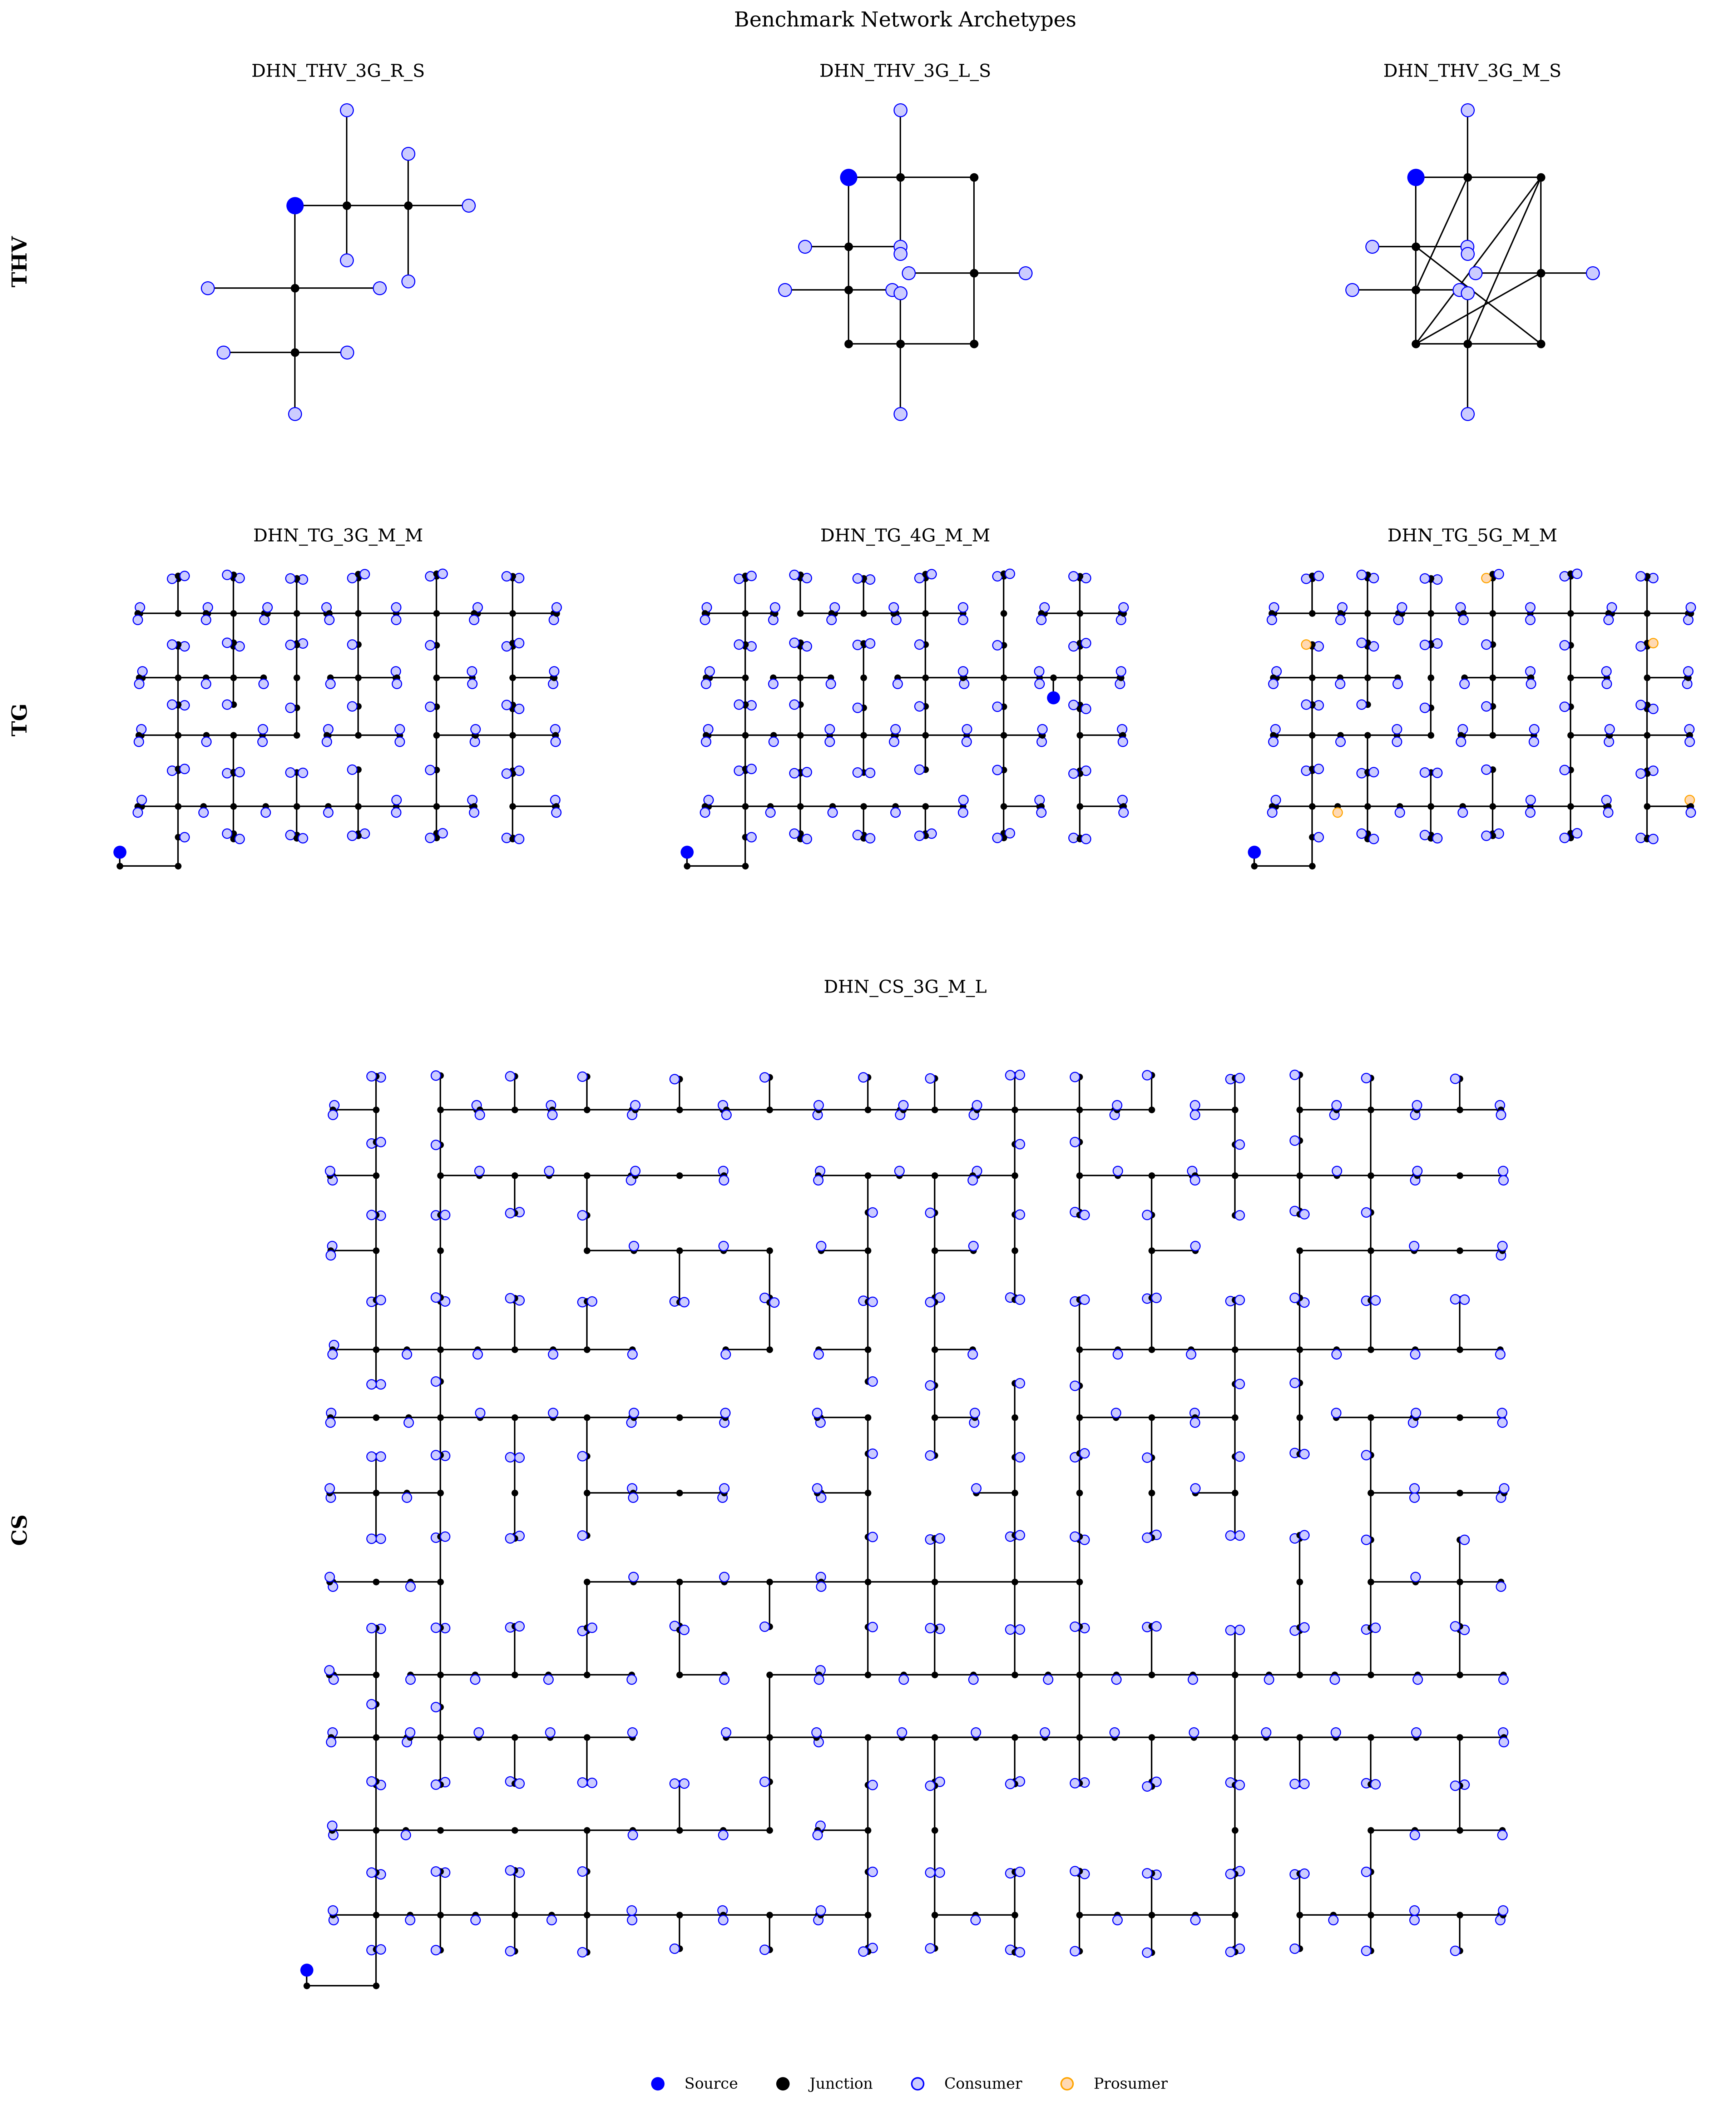

In [7]:
# ---------------------------------------------------------------------------
# All network archetypes, topology overview
# ---------------------------------------------------------------------------
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D

def find_archetypes_dir(anchor_network="DHN_THV_3G_R_S_BASE", max_up=5):
    cur = os.path.abspath(".")
    for _ in range(max_up + 1):
        hits = glob.glob(os.path.join(cur, "**", anchor_network, "nodes.csv"),
                          recursive=True)
        if hits:
            return os.path.dirname(os.path.dirname(hits[0]))
        cur = os.path.dirname(cur)
    return None

ARCHETYPES_DIR = find_archetypes_dir()
if ARCHETYPES_DIR is None:
    raise FileNotFoundError(
        "Could not locate the 'archetypes' folder automatically. Set "
        "ARCHETYPES_DIR manually, e.g.:\n"
        "  ARCHETYPES_DIR = r'C:\\path\\to\\archetypes_generation\\archetypes'"
    )
print("Using ARCHETYPES_DIR =", ARCHETYPES_DIR)

# node style
NODE_STYLE = {
    # type       : (facecolor,    edgecolor,   lw)
    "source"     : ("blue",       "blue",      1.0),
    "junction"   : ("black",      "black",     1.0),
    "substation" : ("#CCCCFF",    "blue",      0.7),
    "prosumer"   : ("#FFD9B3",    "orange",    0.7),
}
DEFAULT_NODE_STYLE = ("gray", "black", 1.0)
_unknown_types_seen = set()

PIPE_COLOR = "black"
FAMILY_PIPE_LW_SCALE = {"THV": 0.5, "TG": 1.0, "CS": 1.0}

FAMILY_FLIP_Y = {"THV": True, "TG": False, "CS": False}

def load_topology(net_name):
    """Node coordinates/types + pipe (from_node, to_node) list."""
    base = os.path.join(ARCHETYPES_DIR, net_name)
    nodes_df = pd.read_csv(os.path.join(base, "nodes.csv"))
    pipes_df = pd.read_csv(os.path.join(base, "pipes.csv"))
    pos   = {r.node_id: (r.x_m, r.y_m) for r in nodes_df.itertuples()}
    ntype = {r.node_id: r.node_type   for r in nodes_df.itertuples()}
    return pos, ntype, pipes_df

def adaptive_style(n_nodes):
    """Scale marker size. """
    marker_size = float(np.clip(1800 / n_nodes, 40, 75))
    line_width  = float(np.clip(45 / n_nodes, 1.0, 1.9))
    return marker_size, line_width

def plot_topology_panel(ax, net_name, title, family):
    """Draw nodes + pipes (plain topology, no flow encoding) on a given axis."""
    pos, ntype, pipes_df = load_topology(net_name)
    marker_size, line_width = adaptive_style(len(pos))
    y_sign = -1 if FAMILY_FLIP_Y.get(family, False) else 1

    pipe_lw = line_width * FAMILY_PIPE_LW_SCALE.get(family, 1.0)

    for row in pipes_df.itertuples():
        u, v = row.from_node, row.to_node
        x1, y1 = pos[u]
        x2, y2 = pos[v]
        ax.plot([x1, x2], [y_sign * y1, y_sign * y2],
                color=PIPE_COLOR, lw=pipe_lw, zorder=2)

    for nid, (x, y) in pos.items():
        t = ntype[nid]
        if t not in NODE_STYLE and t not in _unknown_types_seen:
            print(f"[WARN] unmapped node_type '{t}' in {net_name} — using default style. "
                  f"Add it to NODE_STYLE for a proper colour.")
            _unknown_types_seen.add(t)

        fc, ec, lw = NODE_STYLE.get(t, DEFAULT_NODE_STYLE)

        size = marker_size
        if t == "source":
            size *= 1.5
        elif t == "junction":
            size *= 0.30

        ax.scatter(
            x, y_sign * y,
            s=size,
            color=fc,
            edgecolor=ec,
            linewidth=min(lw, line_width * 1.5),
            zorder=3,
        )

    ax.set_title(title, fontsize=12)
    ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_frame_on(False)
    ax.autoscale()
    ax.margins(0.08)

# --- archetype layout ----------------------------------------------------
ARCHETYPE_LAYOUT = {
    "THV": {
        "DHN_THV_3G_R_S": "DHN_THV_3G_R_S_BASE",
        "DHN_THV_3G_L_S": "DHN_THV_3G_L_S_BASE",
        "DHN_THV_3G_M_S": "DHN_THV_3G_M_S_BASE",
    },
    "TG": {
        "DHN_TG_3G_M_M":  "DHN_TG_3G_M_M_BASE",
        "DHN_TG_4G_M_M":  "DHN_TG_4G_M_M_BASE",
        "DHN_TG_5G_M_M":  "DHN_TG_5G_M_M_BASE",
    },
    "CS": {
        "DHN_CS_3G_M_L":  "DHN_CS_3G_M_L_BASE",
    },
}

fig = plt.figure(figsize=(17, 20))
gs = gridspec.GridSpec(3, 3, figure=fig, hspace=-0.30, wspace=0.12,
                       height_ratios=[1.0, 3.0, 3.0],
                       top=0.95, bottom=0.03, left=0.05, right=0.95)

for family, layout in ARCHETYPE_LAYOUT.items():
    row_idx = list(ARCHETYPE_LAYOUT.keys()).index(family)
    if family == "CS":
        title, net_name = next(iter(layout.items()))
        ax = fig.add_subplot(gs[row_idx, :])
        plot_topology_panel(ax, net_name, title, family)
    else:
        for col, (title, net_name) in enumerate(layout.items()):
            ax = fig.add_subplot(gs[row_idx, col])
            plot_topology_panel(ax, net_name, title, family)

# --- row labels (validation class) ------------------------------------------
grid_pos = gs.get_grid_positions(fig)
bottoms, tops = grid_pos[0], grid_pos[1]
row_order = ["THV", "TG", "CS"]
for row_idx, label in enumerate(row_order):
    y_center = (bottoms[row_idx] + tops[row_idx]) / 2
    fig.text(0.015, y_center, label, fontsize=14, fontweight="bold",
              rotation=90, va="center", ha="center")

# --- shared node-type legend ------------------------------------------------
legend_handles = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor="blue",
           markeredgecolor="blue", markersize=8, label="Source"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="black",
           markeredgecolor="black", markersize=8, label="Junction"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="#CCCCFF",
           markeredgecolor="blue", markersize=8, label="Consumer"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="#FFD9B3",
           markeredgecolor="orange", markersize=8, label="Prosumer"),
]
fig.legend(handles=legend_handles, loc="lower center", ncol=4,
           fontsize=10, frameon=False, bbox_to_anchor=(0.5, 0.008))

fig.suptitle("Benchmark Network Archetypes", fontsize=14, y=0.985)

save_fig(fig, "archetype_topology_overview")
plt.show()

# THV ARCHETYPES

Using ARCHETYPES_DIR = C:\Users\sara.ferrero\PycharmProjects\dhn-benchmark\archetypes_generation\archetypes
[SAVED] THV_supply_flow_direction.png


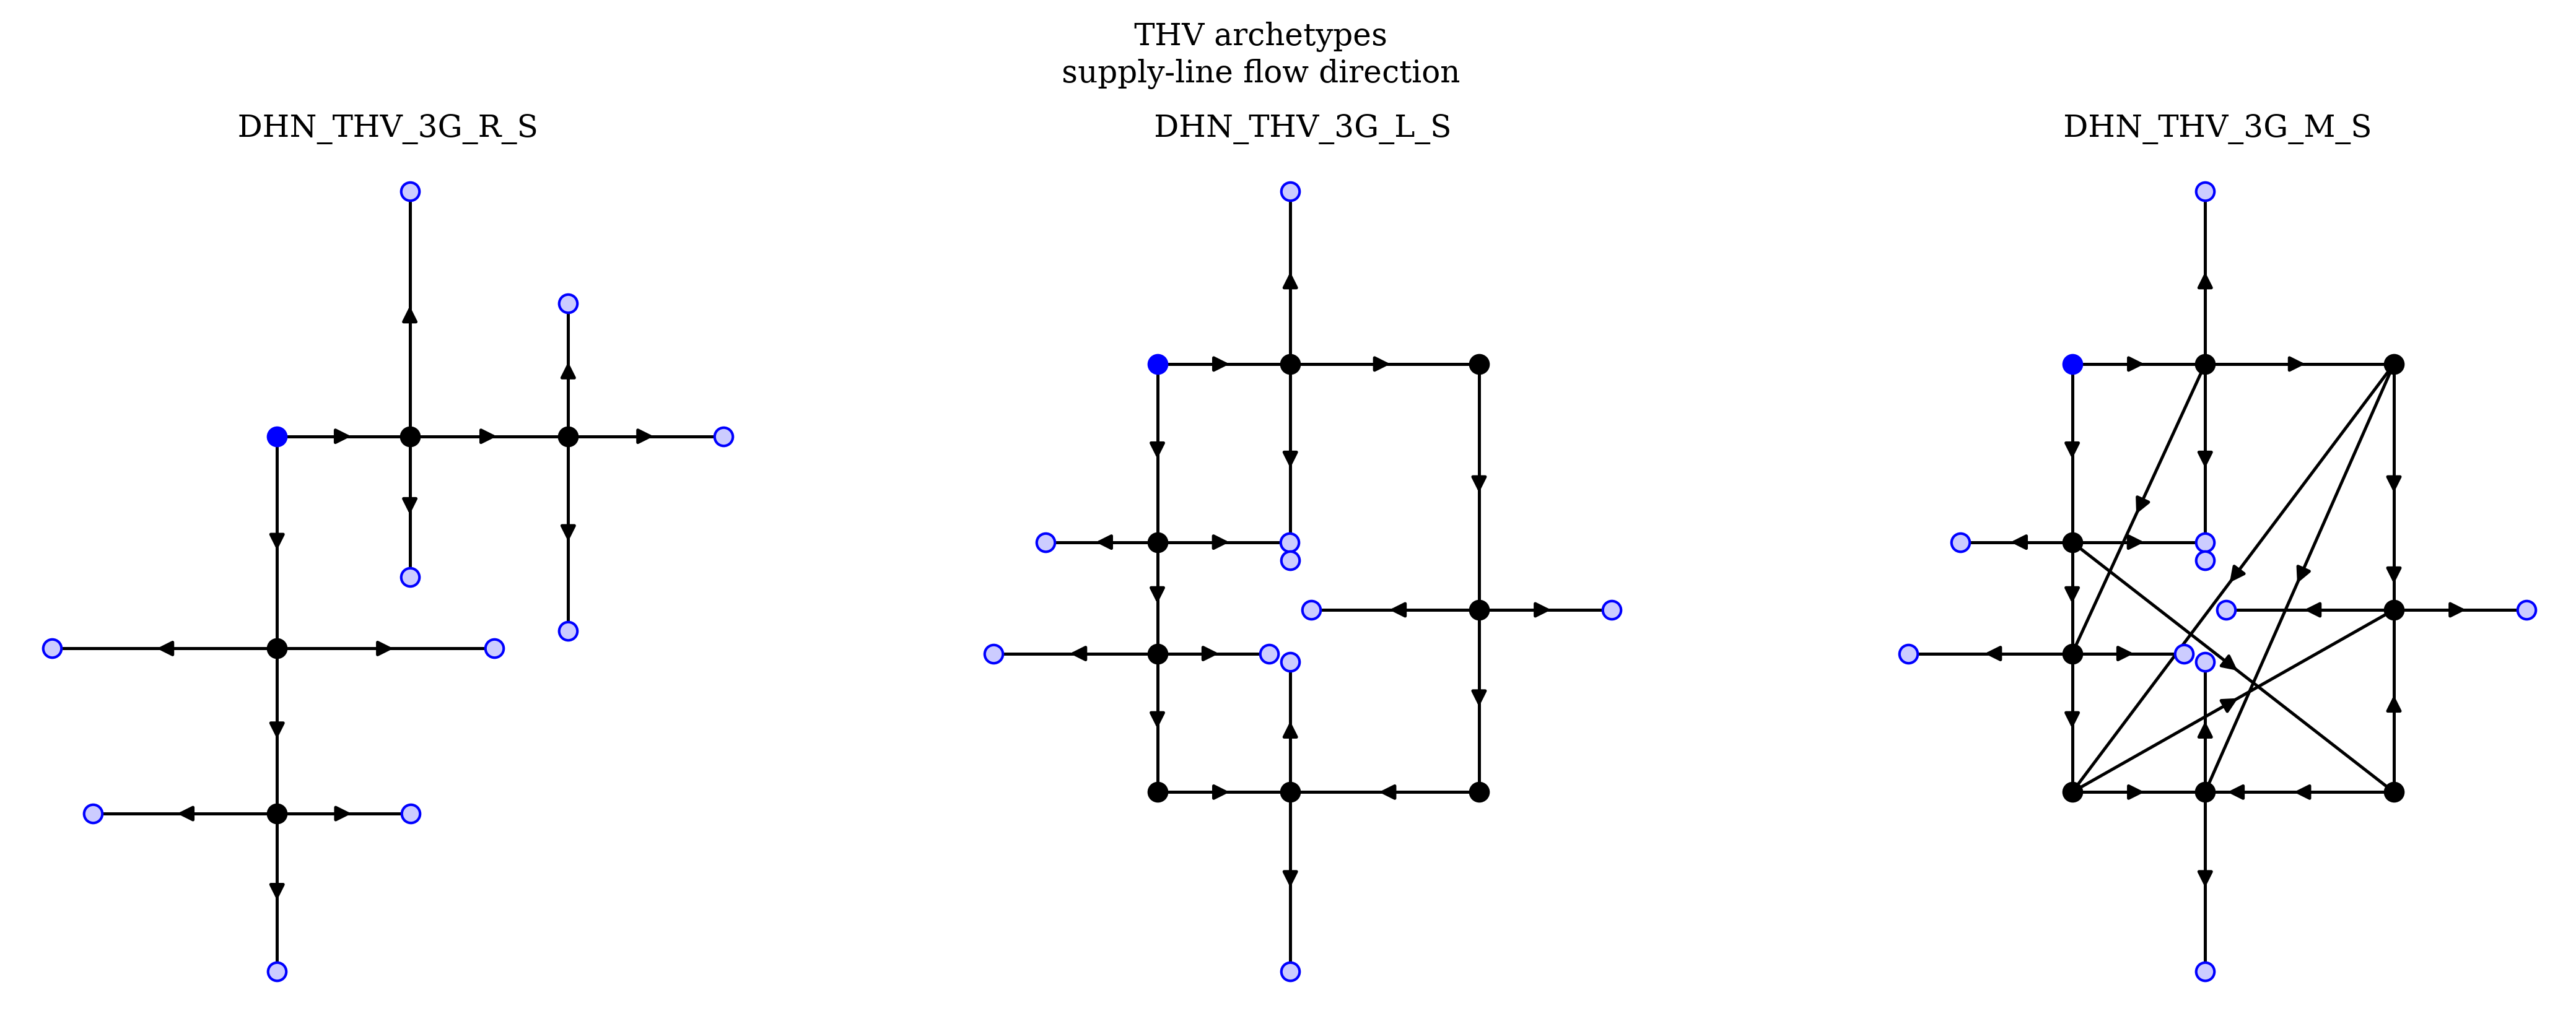

In [8]:
# ---------------------------------------------------------------------------
# THV: network graph FLOW DIRECTION
# ---------------------------------------------------------------------------
import glob
from matplotlib.patches import FancyArrowPatch

def find_archetypes_dir(anchor_network="DHN_THV_3G_R_S_BASE", max_up=5):
    cur = os.path.abspath(".")
    for _ in range(max_up + 1):
        hits = glob.glob(os.path.join(cur, "**", anchor_network, "nodes.csv"),
                          recursive=True)
        if hits:
            return os.path.dirname(os.path.dirname(hits[0]))
        cur = os.path.dirname(cur)
    return None

ARCHETYPES_DIR = find_archetypes_dir()
if ARCHETYPES_DIR is None:
    raise FileNotFoundError(
        "Could not locate the 'archetypes' folder automatically. Set "
        "ARCHETYPES_DIR manually, e.g.:\n"
        "  ARCHETYPES_DIR = r'C:\\path\\to\\archetypes_generation\\archetypes'"
    )
print("Using ARCHETYPES_DIR =", ARCHETYPES_DIR)

THV_ARCHETYPE_NAMES = {
    "DHN_THV_3G_R_S": "DHN_THV_3G_R_S_BASE",
    "DHN_THV_3G_L_S":   "DHN_THV_3G_L_S_BASE",
    "DHN_THV_3G_M_S":   "DHN_THV_3G_M_S_BASE",
}

NODE_STYLE = {
    # type       : (facecolor,  edgecolor, lw)
    "source"     : ("blue",     "blue",    1.0),
    "junction"   : ("black",    "black",   1.0),
    "substation" : ("#CCCCFF",  "blue",    1.0),
}

PIPE_COLOR = "black"
PIPE_LW    = 1.2
ARROW_COLOR = "black"

def load_topology(net_name):
    base = os.path.join(ARCHETYPES_DIR, net_name)
    nodes_df = pd.read_csv(os.path.join(base, "nodes.csv"))
    pipes_df = pd.read_csv(os.path.join(base, "pipes.csv"))
    pos   = {r.node_id: (r.x_m, r.y_m) for r in nodes_df.itertuples()}
    ntype = {r.node_id: r.node_type   for r in nodes_df.itertuples()}
    return pos, ntype, pipes_df

def match_pipe_id(u, v, mdot_index):
    for cand, sign in ((f"{u}_{v}_s", 1), (f"{v}_{u}_s", -1)):
        if cand in mdot_index:
            return cand, sign
    return None, None

supply_mdot_by_network = {}
for label, net_name in THV_ARCHETYPE_NAMES.items():
    supply_mdot_df = THV_NETWORKS[label]["pipe_s_mdot_kgs"]
    supply_mdot_by_network[label] = supply_mdot_df.mean(axis=0)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (label, net_name) in zip(axes, THV_ARCHETYPE_NAMES.items()):
    pos, ntype, pipes_df = load_topology(net_name)
    mdot = supply_mdot_by_network[label]
    mdot_index = set(mdot.index)

    n_matched, n_missed = 0, 0

    for row in pipes_df.itertuples():
        u, v = row.from_node, row.to_node
        col, sign = match_pipe_id(u, v, mdot_index)
        if col is None:
            n_missed += 1
            continue
        m = mdot[col] * sign
        n_matched += 1

        x1, y1 = pos[u]
        x2, y2 = pos[v]

        # --- pipe as a plain line ---
        ax.plot([x1, x2], [-y1, -y2], color=PIPE_COLOR, lw=PIPE_LW, zorder=2)

        # --- direction arrow: u->v if m>=0, else v->u ---
        xm, ym = (x1 + x2) / 2, -(y1 + y2) / 2
        dx, dy = (x2 - x1), -(y2 - y1)
        length = np.hypot(dx, dy)
        if length == 0:
            continue
        ux, uy = dx / length, dy / length
        if m < 0:
            ux, uy = -ux, -uy
        arrow_len = min(20, length * 0.25)
        ax.add_patch(FancyArrowPatch(
            (xm - ux * arrow_len / 2, ym - uy * arrow_len / 2),
            (xm + ux * arrow_len / 2, ym + uy * arrow_len / 2),
            arrowstyle="-|>", mutation_scale=12,
            color=ARROW_COLOR, lw=1.2, zorder=4,
        ))

    for nid, (x, y) in pos.items():
        fc, ec, lw = NODE_STYLE[ntype[nid]]
        ax.scatter(x, -y, s=50, color=fc, edgecolor=ec, linewidth=lw, zorder=3)

    ax.set_title(label, fontsize=12)
    ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_frame_on(False)
    ax.autoscale()

fig.suptitle("THV archetypes\nsupply-line flow direction", fontsize=12, y=1.00)

save_fig(fig, "THV_supply_flow_direction")
plt.show()

DHN_THV_3G_R_S       hydraulics — non-converged timesteps: 0/864 (0.00%)
DHN_THV_3G_R_S       thermal    — non-converged timesteps: 0/864 (0.00%)
DHN_THV_3G_L_S       hydraulics — non-converged timesteps: 0/864 (0.00%)
DHN_THV_3G_L_S       thermal    — non-converged timesteps: 0/864 (0.00%)
DHN_THV_3G_M_S       hydraulics — non-converged timesteps: 0/864 (0.00%)
DHN_THV_3G_M_S       thermal    — non-converged timesteps: 0/864 (0.00%)
[INFO] Zooming row 0 into day 1 — timesteps [144, 288)
[SAVED] THV_solver_convergence.png


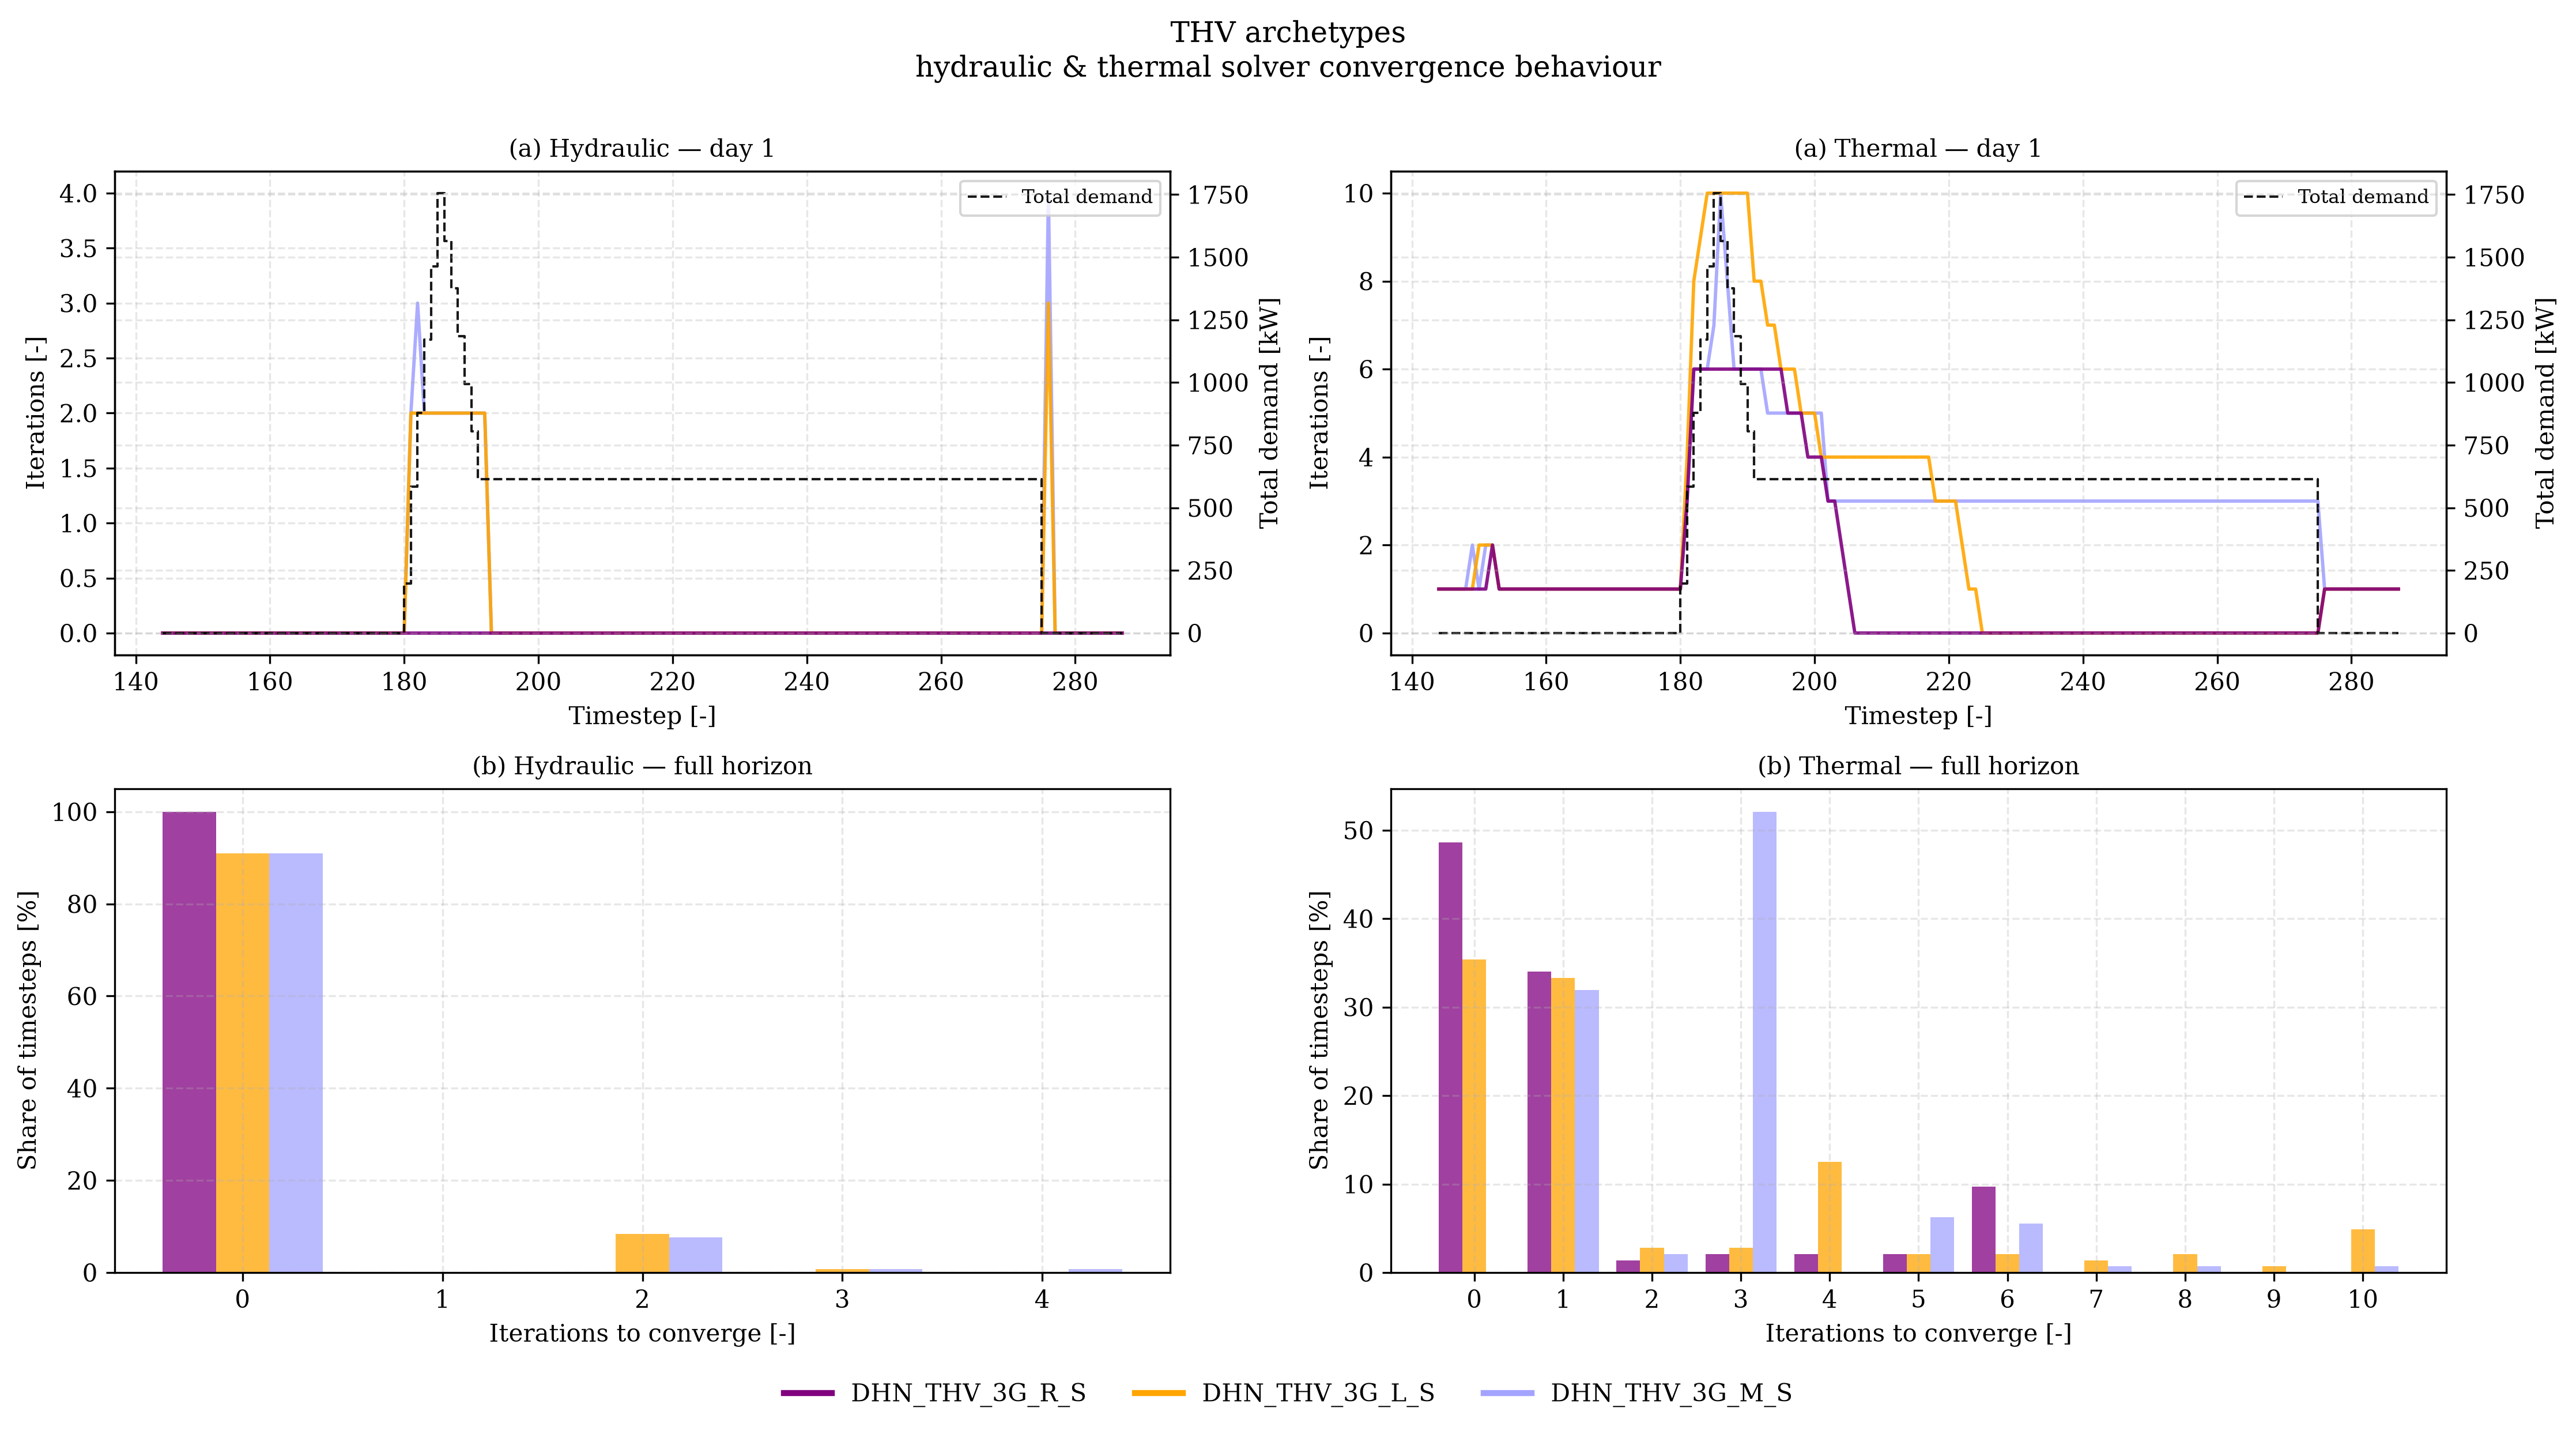

In [9]:
# ---------------------------------------------------------------------------
# THV: hydraulic & thermal solver behaviour
# Row 0: iterations per timestep + demand overlay — single day (dynamics)
# Row 1: iteration-count distribution (bar chart)  — full horizon (statistics)

# ---------------------------------------------------------------------------

for name, net in THV_NETWORKS.items():
    df = net["solver_iteration"]
    n_total = len(df)
    for domain, conv_col in [("hydraulics", "hydraulics_converged"),
                              ("thermal", "thermal_converged")]:
        if conv_col not in df.columns:
            continue
        n_fail = (~df[conv_col].astype(bool)).sum()
        print(f"{name:20s} {domain:10s} — non-converged timesteps: "
              f"{n_fail}/{n_total} ({100*n_fail/n_total:.2f}%)")


from matplotlib.lines import Line2D

STEPS_PER_DAY = 144
DAY_INDEX = None

COLORS = {"DHN_THV_3G_R_S": "purple", "DHN_THV_3G_L_S": "orange", "DHN_THV_3G_M_S": "#A3A3FF"}
ZORDER = {"DHN_THV_3G_R_S": 3, "DHN_THV_3G_L_S": 2, "DHN_THV_3G_M_S": 1}

DOMAIN_CONFIG = {
    "hydraulics": {
        "iter_col": "hydraulics_iterations",
        "label": "Hydraulic",
    },
    "thermal": {
        "iter_col": "thermal_iterations",
        "label": "Thermal",
    },
}

# --- auto-select the "hardest" day (most total iterations, both domains) ---
def select_focus_day():
    total_iter_by_day = {}
    for name, net in THV_NETWORKS.items():
        df = net["solver_iteration"]
        for cfg in DOMAIN_CONFIG.values():
            if cfg["iter_col"] not in df.columns:
                continue
            day_idx = df.index // STEPS_PER_DAY
            per_day = df.groupby(day_idx)[cfg["iter_col"]].sum()
            for day, val in per_day.items():
                total_iter_by_day[day] = total_iter_by_day.get(day, 0) + val
    if not total_iter_by_day:
        return 0
    return max(total_iter_by_day, key=total_iter_by_day.get)

focus_day = DAY_INDEX if DAY_INDEX is not None else select_focus_day()
day_start = focus_day * STEPS_PER_DAY
day_end = day_start + STEPS_PER_DAY
print(f"[INFO] Zooming row 0 into day {focus_day} — timesteps [{day_start}, {day_end})")

fig, axes = plt.subplots(2, 2, figsize=(15, 8), sharex=False)

for col, (domain, cfg) in enumerate(DOMAIN_CONFIG.items()):

    # --- ROW 0: iterations per timestep + total demand overlay, single day --
    ax_iter = axes[0, col]
    ax_demand = ax_iter.twinx()

    demand_plotted = False
    for name, net in THV_NETWORKS.items():
        df = net["solver_iteration"]
        if cfg["iter_col"] not in df.columns:
            print(f"[WARN] '{cfg['iter_col']}' missing for {name} ({domain})")
            continue
        df_day = df[(df.index >= day_start) & (df.index < day_end)]
        ax_iter.plot(df_day.index, df_day[cfg["iter_col"]],
                     color=COLORS.get(name), lw=1.4,
                     alpha=0.9, zorder=ZORDER.get(name, 1))
        if not demand_plotted and "Q_demand_tot_W" in df_day.columns:
            ax_demand.plot(df_day.index, df_day["Q_demand_tot_W"] / 1e3,
                           color="black", lw=1.0, alpha=0.9, linestyle="--",
                           drawstyle="steps",
                           label="Total demand", zorder=0)
            demand_plotted = True

    ax_iter.set_ylabel("Iterations [-]")
    ax_demand.set_ylabel("Total demand [kW]", color="black")
    ax_demand.tick_params(axis="y", colors="black")
    ax_iter.set_xlabel("Timestep [-]")
    ax_iter.set_title(f"(a) {cfg['label']} — day {focus_day}")
    ax_iter.grid(True, alpha=0.3, linestyle="--")
    h2, l2 = ax_demand.get_legend_handles_labels()
    if h2:
        ax_iter.legend(h2, l2, loc="upper right", fontsize=8)

    # --- ROW 1: iteration-count distribution (bar chart), FULL horizon ------
    ax_hist = axes[1, col]
    n_networks = len(THV_NETWORKS)
    bar_width = 0.8 / n_networks
    all_max_iter = 0
    per_network_counts = {}

    for name, net in THV_NETWORKS.items():
        df = net["solver_iteration"]
        if cfg["iter_col"] not in df.columns:
            continue
        counts = df[cfg["iter_col"]].dropna().astype(int).value_counts(normalize=True).sort_index() * 100
        per_network_counts[name] = counts
        all_max_iter = max(all_max_iter, counts.index.max())

    x_range = np.arange(0, all_max_iter + 1)
    for i, (name, counts) in enumerate(per_network_counts.items()):
        y = counts.reindex(x_range, fill_value=0.0)
        offset = (i - (n_networks - 1) / 2) * bar_width
        ax_hist.bar(x_range + offset, y.values, width=bar_width,
                    color=COLORS.get(name), alpha=0.75)

    ax_hist.set_xlabel("Iterations to converge [-]")
    ax_hist.set_ylabel("Share of timesteps [%]")
    ax_hist.set_title(f"(b) {cfg['label']} — full horizon")
    ax_hist.set_xticks(x_range)
    ax_hist.grid(True, axis="y", alpha=0.3, linestyle="--")


network_handles = [Line2D([0], [0], color=COLORS[name], lw=2.5, label=name)
                    for name in THV_NETWORKS.keys()]
fig.legend(handles=network_handles, loc="lower center",
           ncol=len(network_handles), fontsize=10, frameon=False,
           bbox_to_anchor=(0.5, -0.02))

fig.suptitle(f"THV archetypes\nhydraulic & thermal solver convergence behaviour", fontsize=12, y=1.00)
fig.tight_layout(rect=[0, 0.02, 1, 1])

save_fig(fig, "THV_solver_convergence")
plt.show()

# TG ARCHETYPES

[INFO] demand_profile.csv found at: C:\Users\sara.ferrero\PycharmProjects\dhn-benchmark\archetypes_generation\data\demand_profile.csv
[INFO] prosumer_production_profile.csv found at: C:\Users\sara.ferrero\PycharmProjects\dhn-benchmark\archetypes_generation\archetypes\DHN_TG_5G_M_M_BASE\prosumer_production_profile.csv
[SAVED] TG_power_supply.png


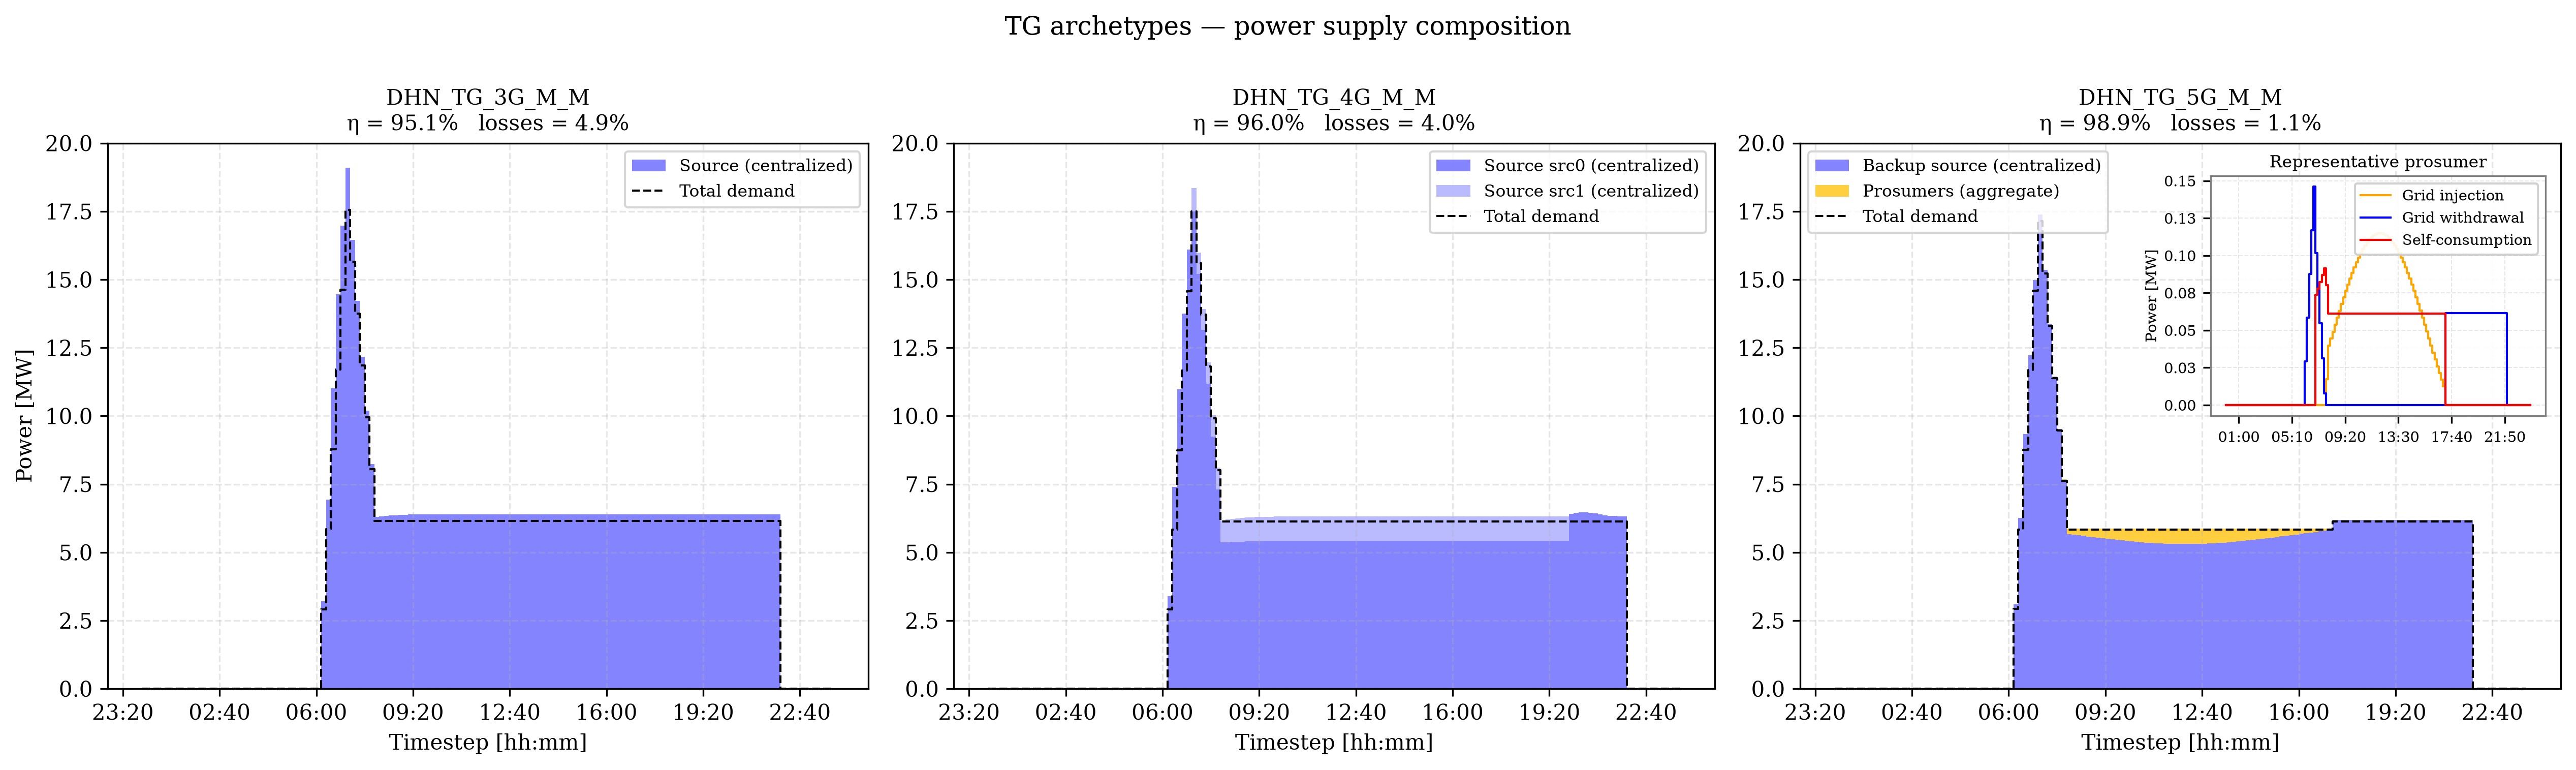

PRODUCTION COMPOSITION BY SOURCE — full simulation horizon

3GDH:
  Source (centralized): 669.6 MWh  (100.0%)

4GDH:
  Source src0 (centralized): 615.3 MWh  (93.1%)
  Source src1 (centralized): 45.8 MWh  (6.9%)

5GDHC:
  Backup source (centralized): 601.4 MWh  (96.5%)
  Prosumers (aggregate):       21.9 MWh  (3.5%)


In [107]:
# ---------------------------------------------------------------------------
# TG: power supply composition
# ---------------------------------------------------------------------------
from matplotlib.ticker import FuncFormatter

COLORS_SRC = ["#5B5BFF", "#A3A3FF", "#FFC000"]

STEPS_PER_DAY = 144
Y_CAP_TOP_ROW = 20.0

def day_window(index, day_index=0):
    start = index.min() + day_index * STEPS_PER_DAY
    end = start + STEPS_PER_DAY
    return start, end

def timestep_to_time(x, pos):
    minutes = int((x % STEPS_PER_DAY) * 10)
    hours = minutes // 60
    mins = minutes % 60
    return f"{hours:02d}:{mins:02d}"

fig, axes_top = plt.subplots(1, 3, figsize=(17, 5))

# --- 3G: single centralized source ------------------------------------------
ax = axes_top[0]
net_3g = TG_NETWORKS["DHN_TG_3G_M_M"]
src_3g = net_3g["source"]["Q_W"] / 1e6   # MW
demand_3g = net_3g["sub_Q_W"].sum(axis=1) / 1e6   # MW

day_start, day_end = day_window(demand_3g.index)
src_3g_day = src_3g[(src_3g.index >= day_start) & (src_3g.index < day_end)]
demand_3g_day = demand_3g[(demand_3g.index >= day_start) & (demand_3g.index < day_end)]

ax.fill_between(src_3g_day.index, 0, src_3g_day.values, step="post",
                color=COLORS_SRC[0], alpha=0.75, edgecolor="none",
                label="Source (centralized)")
ax.step(demand_3g_day.index, demand_3g_day.values, where="post",
        color="black", lw=1.0, linestyle="--", label="Total demand")

eb_3g = net_3g["energy_balance"].iloc[0]
ax.set_title(f"DHN_TG_3G_M_M\n"
             f"η = {100*eb_3g['eta_network']:.1f}%   losses = "
             f"{100*eb_3g['Q_losses_MWh']/eb_3g['Q_produced_MWh']:.1f}%",
             fontsize=10)
ax.set_xlabel("Timestep [hh:mm]")
ax.set_ylabel("Power [MW]")
ax.set_ylim(0, Y_CAP_TOP_ROW)
ax.legend(loc="upper right", fontsize=8)
ax.grid(True, alpha=0.3, linestyle="--")
ax.xaxis.set_major_formatter(FuncFormatter(timestep_to_time))

# --- 4G: two centralized sources --------------------------------------------
ax = axes_top[1]
net_4g = TG_NETWORKS["DHN_TG_4G_M_M"]
src_4g = net_4g["src_Q_W"] / 1e6
demand_4g = net_4g["sub_Q_W"].sum(axis=1) / 1e6

day_start, day_end = day_window(demand_4g.index)
src_4g_day = src_4g[(src_4g.index >= day_start) & (src_4g.index < day_end)]
demand_4g_day = demand_4g[(demand_4g.index >= day_start) & (demand_4g.index < day_end)]

bottom = np.zeros(len(src_4g_day))
for i, c in enumerate(src_4g_day.columns):
    top = bottom + src_4g_day[c].values
    ax.fill_between(src_4g_day.index, bottom, top, step="post",
                     color=COLORS_SRC[i], alpha=0.75, edgecolor="none",
                     label=f"Source {c} (centralized)")
    bottom = top

ax.step(demand_4g_day.index, demand_4g_day.values, where="post",
        color="black", lw=1.0, linestyle="--", label="Total demand")

eb_4g = net_4g["energy_balance"].iloc[0]
ax.set_title(f"DHN_TG_4G_M_M\n"
             f"η = {100*eb_4g['eta_network']:.1f}%   losses = "
             f"{100*eb_4g['Q_losses_MWh']/eb_4g['Q_produced_MWh']:.1f}%",
             fontsize=10)
ax.set_xlabel("Timestep [hh:mm]")
ax.set_ylim(0, Y_CAP_TOP_ROW)
ax.legend(loc="upper right", fontsize=8, ncol=1)
ax.grid(True, alpha=0.3, linestyle="--")
ax.xaxis.set_major_formatter(FuncFormatter(timestep_to_time))

# --- 5G: backup source + AGGREGATE prosumer, with inset decomposition ------
ax = axes_top[2]
net_5g = TG_NETWORKS["DHN_TG_5G_M_M"]
src_5g = net_5g["src_Q_W"]
prod_5g = net_5g["pro_prod_Q_W"] / 1e6
cons_5g = net_5g["pro_cons_Q_W"] / 1e6
sub_5g_demand = net_5g["sub_Q_W"].sum(axis=1) / 1e6

src_5g_MW = src_5g["src"] / 1e6
prod_5g_agg = prod_5g.sum(axis=1)
demand_5g = sub_5g_demand + cons_5g.sum(axis=1)

day_start, day_end = day_window(demand_5g.index)
src_5g_day = src_5g_MW[(src_5g_MW.index >= day_start) & (src_5g_MW.index < day_end)]
prod_5g_agg_day = prod_5g_agg[(prod_5g_agg.index >= day_start) & (prod_5g_agg.index < day_end)]
demand_5g_day = demand_5g[(demand_5g.index >= day_start) & (demand_5g.index < day_end)]

bottom = np.zeros(len(src_5g_day))
top = bottom + src_5g_day.values
ax.fill_between(src_5g_day.index, bottom, top, step="post",
                color=COLORS_SRC[0], alpha=0.75, edgecolor="none",
                label="Backup source (centralized)")
bottom = top
top = bottom + prod_5g_agg_day.values
ax.fill_between(prod_5g_agg_day.index, bottom, top, step="post",
                color=COLORS_SRC[2], alpha=0.75, edgecolor="none",
                label="Prosumers (aggregate)")

ax.step(demand_5g_day.index, demand_5g_day.values, where="post",
        color="black", lw=1.0, linestyle="--", label="Total demand")

eb_5g = net_5g["energy_balance"].iloc[0]
ax.set_title(f"DHN_TG_5G_M_M\n"
             f"η = {100*eb_5g['eta_network']:.1f}%   losses = "
             f"{100*eb_5g['Q_losses_MWh']/eb_5g['Q_produced_MWh']:.1f}%",
             fontsize=10)
ax.set_xlabel("Timestep [hh:mm]")
ax.set_ylim(0, Y_CAP_TOP_ROW)
ax.legend(loc="upper right", fontsize=8, ncol=1)
ax.grid(True, alpha=0.3, linestyle="--")
ax.xaxis.set_major_formatter(FuncFormatter(timestep_to_time))

# --- INSET: representative prosumer — self-consumption / injection / withdrawal
rep_cons_col = cons_5g.columns[0]
rep_prod_col = f"{rep_cons_col}_prod"

grid_injection = prod_5g[(prod_5g.index >= day_start) & (prod_5g.index < day_end)][rep_prod_col]
grid_withdrawal = cons_5g[(cons_5g.index >= day_start) & (cons_5g.index < day_end)][rep_cons_col].abs()

import glob

def find_file_near(anchor_dir, filename, max_up=4):
    """Search for `filename` starting from anchor_dir, then walking up the
    tree and searching recursively at each level."""
    cur = anchor_dir
    for _ in range(max_up + 1):
        hits = glob.glob(os.path.join(cur, "**", filename), recursive=True)
        if hits:
            return hits[0]
        cur = os.path.dirname(cur)
    return None

net_5g_dir = os.path.join(ARCHETYPES_DIR, "DHN_TG_5G_M_M_BASE")

demand_profile_path = find_file_near(net_5g_dir, "demand_profile.csv")
prod_profile_path   = find_file_near(net_5g_dir, "prosumer_production_profile.csv")

print(f"[INFO] demand_profile.csv found at: {demand_profile_path}")
print(f"[INFO] prosumer_production_profile.csv found at: {prod_profile_path}")

if demand_profile_path is None or prod_profile_path is None:
    raise FileNotFoundError(
        "Could not locate the raw prosumer profile files automatically. "
        "Set demand_profile_path / prod_profile_path manually, e.g.:\n"
        "  demand_profile_path = r'C:\\...\\data\\demand_profile.csv'\n"
        "  prod_profile_path   = r'C:\\...\\DHN_TG_5G_M_M_BASE\\prosumer_production_profile.csv'"
    )

demand_profile_raw = pd.read_csv(demand_profile_path)
prod_profile_raw   = pd.read_csv(prod_profile_path)

SKIP = 144   # must match the SKIP used in the results-export script

consumption_prosumer_full = (demand_profile_raw["Q_W"] / 1e6).iloc[SKIP:]   # MW
production_prosumer_full  = (prod_profile_raw["Q_W"] / 1e6).iloc[SKIP:]     # MW

# align to the same timestep index used elsewhere
consumption_prosumer_full.index = TG_NETWORKS["DHN_TG_5G_M_M"]["sub_Q_W"].index[:len(consumption_prosumer_full)]
production_prosumer_full.index  = consumption_prosumer_full.index

self_prosumer_full = np.minimum(consumption_prosumer_full, production_prosumer_full)
self_consumption = self_prosumer_full[(self_prosumer_full.index >= day_start) &
                                       (self_prosumer_full.index < day_end)]

# align to the same timestep index used elsewhere (assumes row order == timestep order)
consumption_prosumer_full.index = TG_NETWORKS["DHN_TG_5G_M_M"]["sub_Q_W"].index[:len(consumption_prosumer_full)]
production_prosumer_full.index  = consumption_prosumer_full.index

self_prosumer_full = np.minimum(consumption_prosumer_full, production_prosumer_full)
self_consumption = self_prosumer_full[(self_prosumer_full.index >= day_start) &
                                       (self_prosumer_full.index < day_end)]

ax.legend(loc="upper left", fontsize=8, ncol=1)

# --- INSET: representative prosumer — self-consumption / injection / withdrawal
ax_inset = ax.inset_axes([0.54, 0.50, 0.44, 0.44])

ax_inset.step(grid_injection.index, grid_injection, where="post",
              color="orange", lw=1.0, label="Grid injection", zorder=2)
ax_inset.step(grid_withdrawal.index, grid_withdrawal, where="post",
              color="blue", lw=1.0, label="Grid withdrawal", zorder=2)
ax_inset.step(self_consumption.index, self_consumption, where="post",
              color="red", lw=1.0, label="Self-consumption", zorder=3)

ax_inset.set_title("Representative prosumer", fontsize=8, pad=4)
ax_inset.set_ylabel("Power [MW]", fontsize=7, labelpad=2)
ax_inset.tick_params(labelsize=7)
ax_inset.yaxis.set_major_formatter(FuncFormatter(lambda v, pos: f"{v:.2f}"))
ax_inset.xaxis.set_major_formatter(FuncFormatter(timestep_to_time))
ax_inset.legend(fontsize=7, loc="upper right", framealpha=0.9)
ax_inset.grid(True, alpha=0.3, linestyle="--", linewidth=0.5)

for spine in ax_inset.spines.values():
    spine.set_edgecolor("gray")
    spine.set_linewidth(0.8)
ax_inset.set_facecolor("white")
ax_inset.patch.set_alpha(0.92)



fig.suptitle("TG archetypes — power supply composition", fontsize=12, y=1.00)
fig.tight_layout()

save_fig(fig, "TG_power_supply")
plt.show()

# ---------------------------------------------------------------------------
# PRINT: total production composition by source, per generation [%]
# ---------------------------------------------------------------------------
STEPSIZE_H = 10 / 60   # hours per timestep — adjust if resolution differs

print("=" * 60)
print("PRODUCTION COMPOSITION BY SOURCE — full simulation horizon")
print("=" * 60)

# --- 3G ---
E_3g_src = (src_3g * STEPSIZE_H).sum()
print(f"\n3GDH:")
print(f"  Source (centralized): {E_3g_src:.1f} MWh  (100.0%)")

# --- 4G ---
E_4g_src = (src_4g * STEPSIZE_H).sum()   # Series, per source column
E_4g_tot = E_4g_src.sum()
print(f"\n4GDH:")
for col in E_4g_src.index:
    pct = 100 * E_4g_src[col] / E_4g_tot
    print(f"  Source {col} (centralized): {E_4g_src[col]:.1f} MWh  ({pct:.1f}%)")

# --- 5G ---
E_5g_src = (src_5g_MW * STEPSIZE_H).sum()
E_5g_prod_agg = (prod_5g_agg * STEPSIZE_H).sum()
E_5g_tot = E_5g_src + E_5g_prod_agg
print(f"\n5GDHC:")
print(f"  Backup source (centralized): {E_5g_src:.1f} MWh  "
      f"({100*E_5g_src/E_5g_tot:.1f}%)")
print(f"  Prosumers (aggregate):       {E_5g_prod_agg:.1f} MWh  "
      f"({100*E_5g_prod_agg/E_5g_tot:.1f}%)")

print("=" * 60)

[SAVED] TG_temperature_regime.png


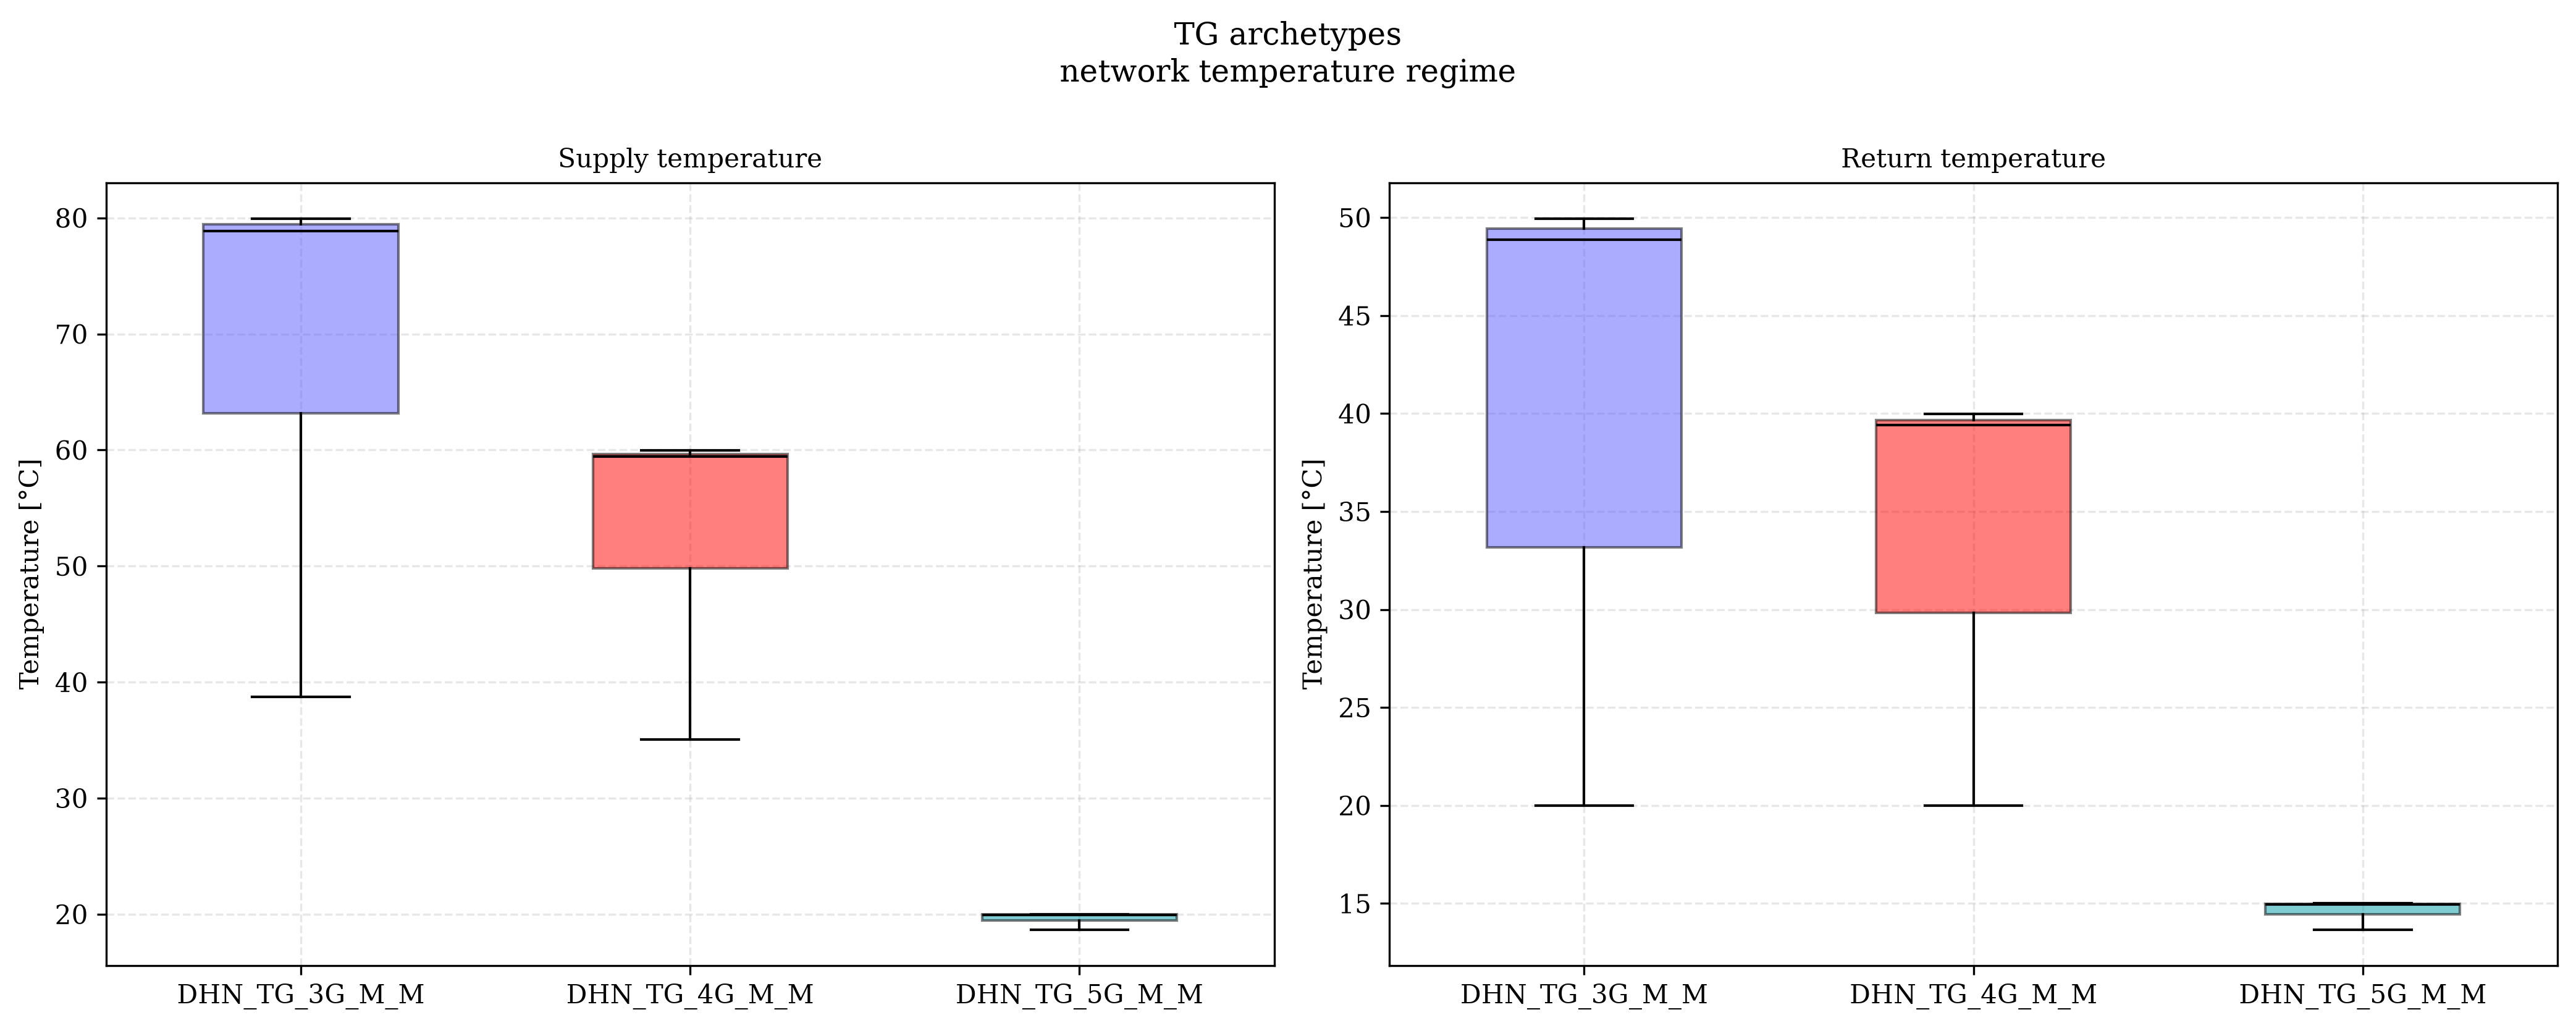

In [11]:
# ---------------------------------------------------------------------------
# TG: network temperature regime by generation
# ---------------------------------------------------------------------------
TG_LABELS = {
    "DHN_TG_3G_M_M": "DHN_TG_3G_M_M",
    "DHN_TG_4G_M_M": "DHN_TG_4G_M_M",
    "DHN_TG_5G_M_M": "DHN_TG_5G_M_M",
}
COLORS_GEN = {"DHN_TG_3G_M_M": "#5B5BFF", "DHN_TG_4G_M_M": "#FF0000", "DHN_TG_5G_M_M": "#009AA6"}

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# --- LEFT: supply temperature distribution across all substations -
ax = axes[0]
box_data, box_labels, box_colors = [], [], []
for key, label in TG_LABELS.items():
    net = TG_NETWORKS[key]
    T_supply = net["sub_T_supply_degC"]
    box_data.append(T_supply.values.flatten())
    box_labels.append(label)
    box_colors.append(COLORS_GEN[key])

bp = ax.boxplot(box_data, tick_labels=box_labels, patch_artist=True, showfliers=False, widths=0.5)
for patch, c in zip(bp["boxes"], box_colors):
    patch.set_facecolor(c)
    patch.set_alpha(0.5)
for median in bp["medians"]:
    median.set_color("black")

ax.set_ylabel("Temperature [°C]")
ax.set_title("Supply temperature")
ax.grid(True, axis="y", alpha=0.3, linestyle="--")

# --- RIGHT: return temperature distribution -------------------------------
ax = axes[1]
box_data, box_labels, box_colors = [], [], []
for key, label in TG_LABELS.items():
    net = TG_NETWORKS[key]
    T_return = net["sub_T_return_degC"]
    box_data.append(T_return.values.flatten())
    box_labels.append(label)
    box_colors.append(COLORS_GEN[key])

bp = ax.boxplot(box_data, tick_labels=box_labels, patch_artist=True, showfliers=False, widths=0.5)
for patch, c in zip(bp["boxes"], box_colors):
    patch.set_facecolor(c)
    patch.set_alpha(0.5)
for median in bp["medians"]:
    median.set_color("black")

ax.set_ylabel("Temperature [°C]")
ax.set_title("Return temperature")
ax.grid(True, axis="y", alpha=0.3, linestyle="--")

fig.suptitle("TG archetypes\nnetwork temperature regime", fontsize=12, y=1.00)
fig.tight_layout()

save_fig(fig, "TG_temperature_regime")
plt.show()

# CS ARCHETYPES

[SAVED] CS_computational_scalability.png


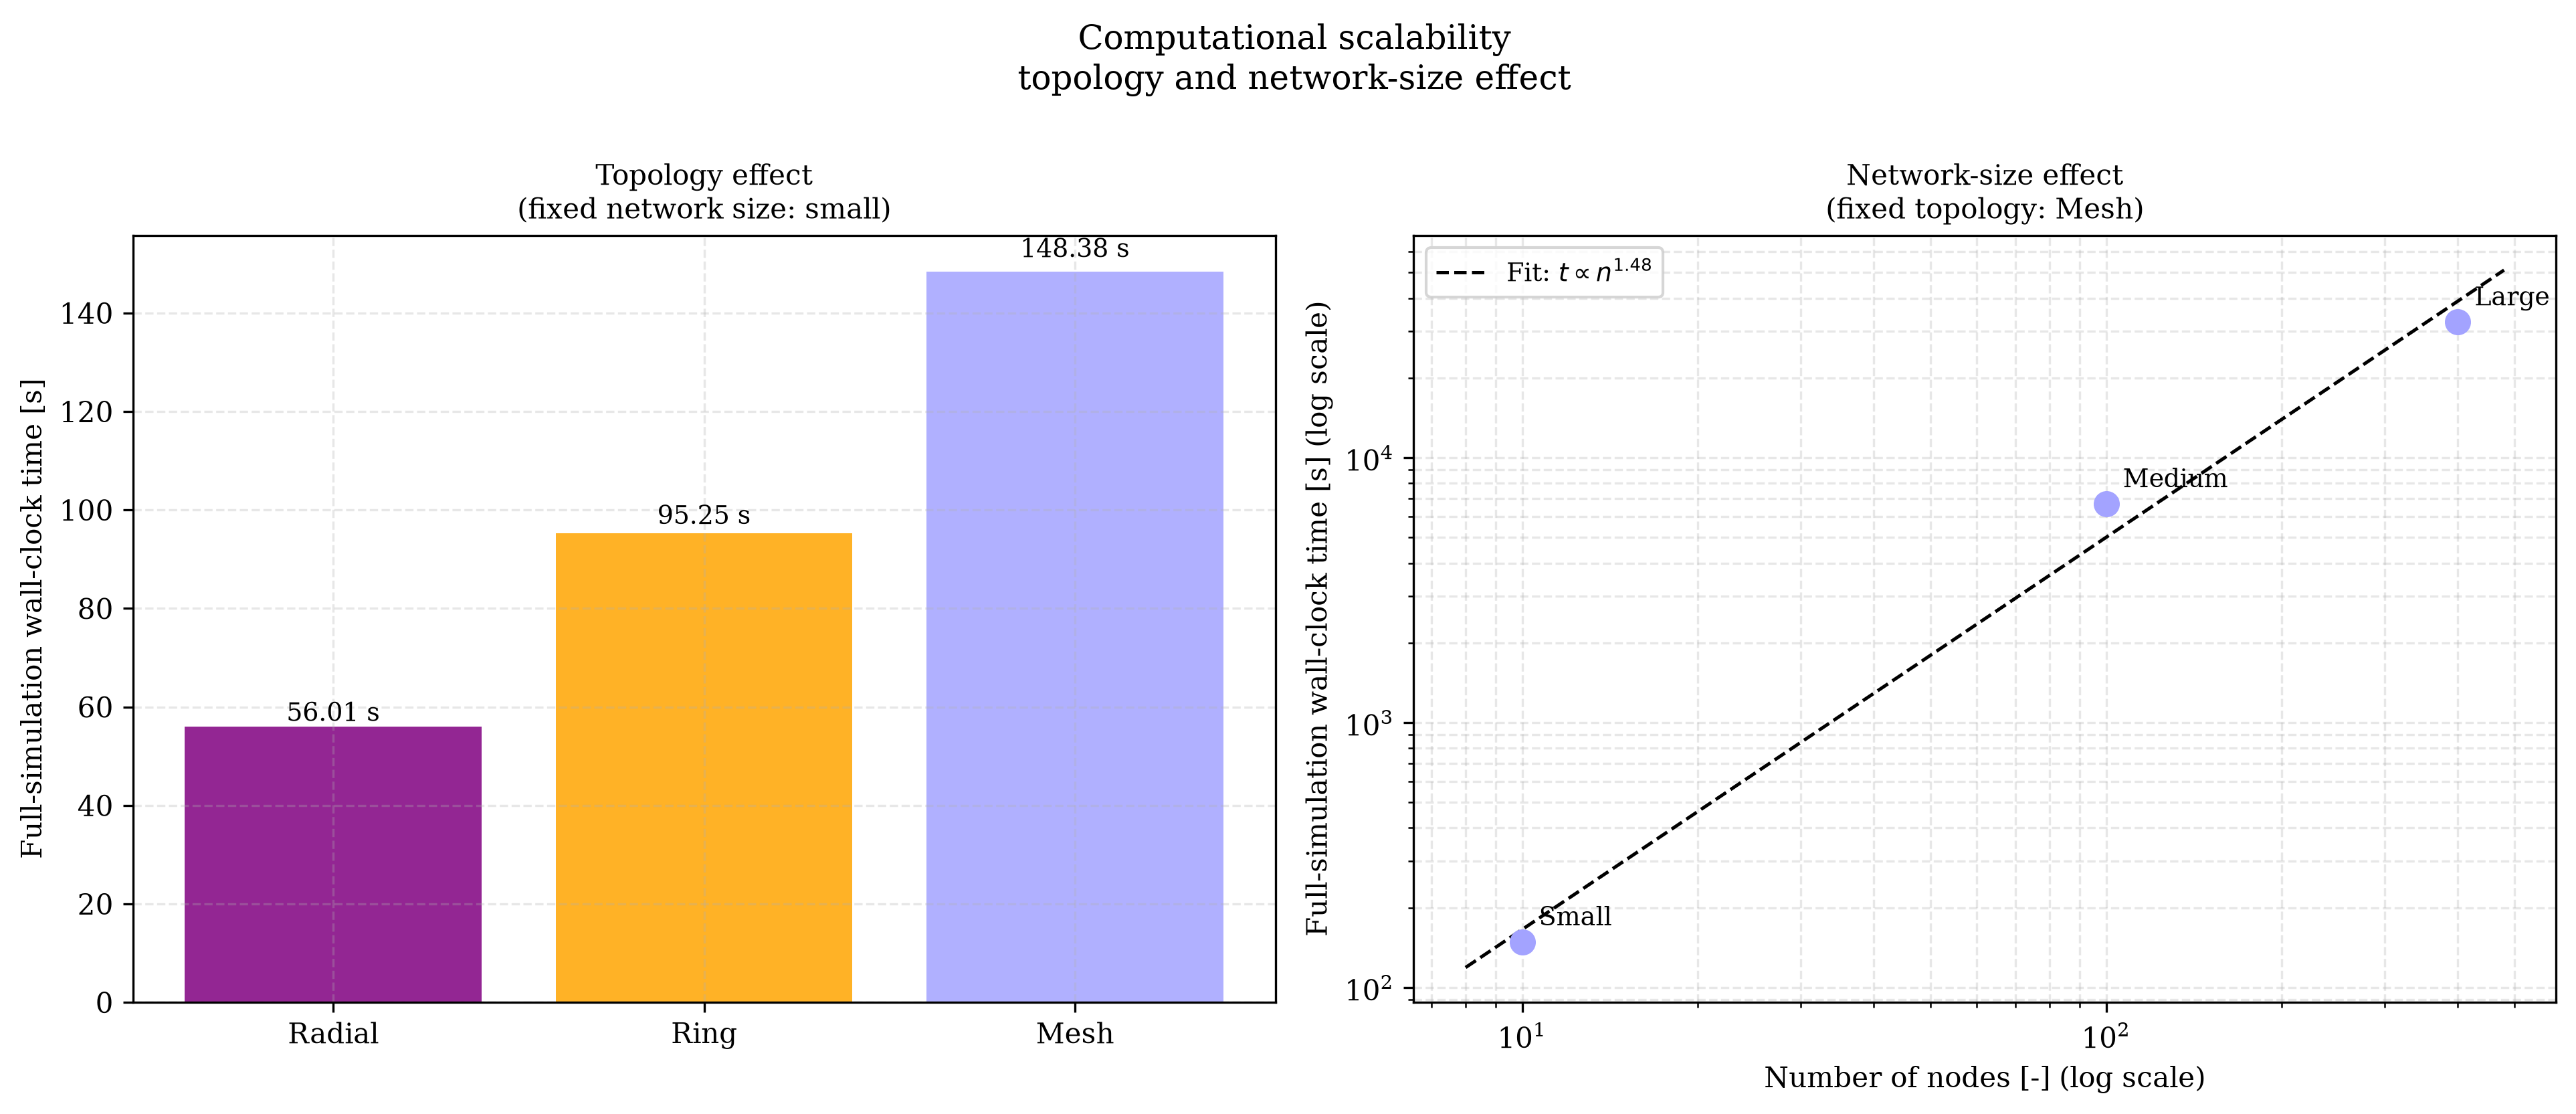

In [13]:
# ---------------------------------------------------------------------------
# CS: computational scalability — topology effect (fixed size) and
#     network-size effect (fixed topology), full-simulation wall-clock time
# ---------------------------------------------------------------------------
SIM_TIME_S = {
    "DHN_THV_3G_R_S": 56.01,    # small, Radial
    "DHN_THV_3G_L_S": 95.25,    # small, Ring
    "DHN_THV_3G_M_S": 148.38,   # small, Mesh
    "DHN_TG_3G_M_M":  6690.50,  # medium, Mesh
    "DHN_CS_3G_M_L":  32506.93, # large, Mesh
}

# node counts
N_NODES = {
    "DHN_THV_3G_R_S": 100,
    "DHN_THV_3G_L_S": 10,
    "DHN_THV_3G_M_S": 10,
    "DHN_TG_3G_M_M":  100,
    "DHN_CS_3G_M_L":  400,
}

missing = [k for k, v in SIM_TIME_S.items() if v is None]
if missing:
    raise ValueError(f"Fill in SIM_TIME_S for: {missing}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

# --- Panel 1: topology effect, fixed (small) size ---------------------------
ax = axes[0]
topo_keys = ["DHN_THV_3G_R_S", "DHN_THV_3G_L_S", "DHN_THV_3G_M_S"]
topo_labels = ["Radial", "Ring", "Mesh"]
topo_colors = ["purple", "orange", "#A3A3FF"]
topo_times = [SIM_TIME_S[k] for k in topo_keys]

ax.bar(topo_labels, topo_times, color=topo_colors, alpha=0.85)
for i, t in enumerate(topo_times):
    ax.text(i, t * 1.02, f"{t:.2f} s", ha="center", fontsize=9)
ax.set_ylabel("Full-simulation wall-clock time [s]")
ax.set_title("Topology effect\n(fixed network size: small)")
ax.grid(True, axis="y", alpha=0.3, linestyle="--")

# --- Panel 2: network-size effect, fixed (Mesh) topology, log-log ----------
ax = axes[1]
size_keys = ["DHN_THV_3G_M_S", "DHN_TG_3G_M_M", "DHN_CS_3G_M_L"]
size_labels = ["Small", "Medium", "Large"]
n_nodes = np.array([N_NODES[k] for k in size_keys])
sim_times = np.array([SIM_TIME_S[k] for k in size_keys])

ax.scatter(n_nodes, sim_times, color="#A3A3FF", s=70, zorder=3)
for n, t, label in zip(n_nodes, sim_times, size_labels):
    ax.annotate(label, (n, t), textcoords="offset points", xytext=(6, 6), fontsize=9)

# power-law fit: log(t) = k*log(n) + log(C)  ->  t = C * n^k
log_n, log_t = np.log(n_nodes), np.log(sim_times)
k_fit, log_C = np.polyfit(log_n, log_t, 1)
n_fit = np.linspace(n_nodes.min() * 0.8, n_nodes.max() * 1.2, 100)
t_fit = np.exp(log_C) * n_fit ** k_fit
ax.plot(n_fit, t_fit, color="black", linestyle="--", lw=1.2,
        label=f"Fit: $t \\propto n^{{{k_fit:.2f}}}$")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Number of nodes [-] (log scale)")
ax.set_ylabel("Full-simulation wall-clock time [s] (log scale)")
ax.set_title("Network-size effect\n(fixed topology: Mesh)")
ax.legend(fontsize=9)
ax.grid(True, which="both", alpha=0.3, linestyle="--")

fig.suptitle("Computational scalability\ntopology and network-size effect",
             fontsize=12, y=1.00)
fig.tight_layout()

save_fig(fig, "CS_computational_scalability")
plt.show()